# Keypoints group prediction

In [1]:
BASE_FOLDER = '/home/asyeda/stringerlab_dm11/eye-vs-face/' # set path parent folder called eye-vs-facce which should contain 'data' folder

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys
sys.path.append(os.path.join(BASE_FOLDER, 'analysis/code'))
import nonlinear_modelv3
import helper_functions
import torch
import torch.nn.functional as F
import torch.nn.utils as torch_utils
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.optim as optim
import pupil_dark_helpers as pdh
import pandas as pd
import seaborn as sns
from tqdm import tqdm
import matplotlib
from sklearn.decomposition import PCA

### Load all mice data

In [3]:
dark_dbs = pdh.carbachol_in_dark() 
light_random_dbs = pdh.get_light_random_info()
light_static_dbs = pdh.get_light_static_info()

dbs = [dark_dbs, light_random_dbs, light_static_dbs]
category = ['dark', 'light_random', 'light_static']

Sessions from carbachol_in_dark >>>
Sessions from get_light_random_info >>>
Sessions from get_light_static_info >>>


## Temporal model

In [4]:
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
import torch
import numpy as np

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Function to prepare input data
def prepare_input_data(pose_x_coord, pose_y_coord):
    """
    Combine pose_x_coord and pose_y_coord into a single input array.
    """
    input_data = np.stack([pose_x_coord, pose_y_coord], axis=2).reshape(pose_x_coord.shape[0], -1)
    return input_data

# Function to create sequences from input data
def create_sequences(data, targets, sequence_length=1000, padding=50):
    """
    Create sequences of input data and corresponding targets.
    """
    sequences = []
    target_sequences = []
    seq_start = 0
    seq_end = sequence_length
    while seq_end < len(data):
        sequences.append(data[seq_start:seq_end])
        target_sequences.append(targets[seq_start:seq_end])
        seq_start += sequence_length + padding
        seq_end += sequence_length + padding
    
    return np.array(sequences), np.array(target_sequences)

def split_data(input_data, output_data, val_size=0.1, test_size=0.1, output_dtype=None, device='cuda'):
    """
    Split data into training, validation, and test sets, and normalize features and targets.

    Parameters
    ----------
    input_data : np.ndarray
        Input features.
    output_data : np.ndarray
        Output targets.
    val_size : float
        Fraction of data to use for validation.
    test_size : float
        Fraction of data to use for testing.
    output_dtype : torch.dtype, optional
        Data type for output tensors.
    device : str
        Device to move tensors to ('cuda' or 'cpu').

    Returns
    -------
    (X_train, X_val, X_test, y_train, y_val, y_test, idx_train, idx_val, idx_test)
    """

    # First split off the test set
    idx_trainval, idx_test = train_test_split(
        np.arange(input_data.shape[0]), test_size=test_size, shuffle=True
    )

    # Then split the remaining into train and val
    val_fraction_of_trainval = val_size / (1.0 - test_size)
    idx_train, idx_val = train_test_split(
        idx_trainval, test_size=val_fraction_of_trainval, shuffle=True
    )

    # Flatten (in case indices are chunked arrays)
    idx_train, idx_val, idx_test = map(lambda x: x.flatten(), [idx_train, idx_val, idx_test])
    # Ensure splits are disjoint
    assert len(set(idx_train) & set(idx_val)) == 0    # train ∩ val = ∅
    assert len(set(idx_train) & set(idx_test)) == 0   # train ∩ test = ∅
    assert len(set(idx_val) & set(idx_test)) == 0     # val ∩ test = ∅

    # Slice data
    X_train, X_val, X_test = input_data[idx_train], input_data[idx_val], input_data[idx_test]
    y_train, y_val, y_test = output_data[idx_train], output_data[idx_val], output_data[idx_test]

    print("train/val/test split:",
          X_train.shape, X_val.shape, X_test.shape,
          y_train.shape, y_val.shape, y_test.shape)

    # Convert to PyTorch tensors and move to device
    X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)

    if output_dtype is None:
        output_dtype = torch.float32

    y_train_tensor = torch.tensor(y_train, dtype=output_dtype).to(device)
    y_val_tensor = torch.tensor(y_val, dtype=output_dtype).to(device)
    y_test_tensor = torch.tensor(y_test, dtype=output_dtype).to(device)

    return (
        X_train_tensor, X_val_tensor, X_test_tensor,
        y_train_tensor, y_val_tensor, y_test_tensor,
        idx_train, idx_val, idx_test
    )

# Function to create dataloaders
def create_dataloaders(X_train, y_train, X_val, y_val, X_test, y_test, batch_size=16):
    """
    Create PyTorch dataloaders for training, validation, and test datasets.

    Parameters
    ----------
    X_train, y_train : torch.Tensor
        Training data and labels.
    X_val, y_val : torch.Tensor
        Validation data and labels.
    X_test, y_test : torch.Tensor
        Test data and labels.
    batch_size : int
        Number of samples per batch.

    Returns
    -------
    train_loader, val_loader, test_loader : DataLoader
        PyTorch DataLoaders for training, validation, and test sets.
    """
    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)
    test_dataset = TensorDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader

def gabor_wavelet(sigma, freq, phase, n_pts=101):
    t = np.linspace(-1, 1, n_pts)
    g = np.exp(-t**2 / (2 * sigma**2)) * np.cos(2 * np.pi * freq * t + phase)
    return g.astype("float32")

class GroupsTCN(nn.Module):
    def __init__(self, input_dim, output_dim, conv_filters=32, kernel_size=101, dropout=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.conv_filters = conv_filters

        # Initial projection
        self.conv_in = nn.Conv1d(input_dim, conv_filters, kernel_size=1)

        # Temporal convolutional stack (dilated residual blocks)
        dilations = [1, 2, 4]
        layers = []
        for d in dilations:
            layers.append(ResidualBlock(conv_filters, kernel_size, d, dropout))
        self.tcn = nn.Sequential(*layers)

        # Output projection (1x1 conv → same sequence length)
        self.conv_out = nn.Conv1d(conv_filters, output_dim, kernel_size=1)

        # Optional: initialize first layer filters with Gabor wavelets
        self.init_gabor(self.tcn[0].conv1, kernel_size)

    def init_gabor(self, conv, kernel_size):
        f = np.geomspace(1, 10, self.conv_filters // 2).astype("float32")
        gw0 = gabor_wavelet(0.25, f[:, np.newaxis], 0, n_pts=kernel_size)
        gw1 = gabor_wavelet(0.25, f[:, np.newaxis], np.pi / 2, n_pts=kernel_size)
        wav_init = np.vstack((gw0, gw1))
        wav_init = torch.from_numpy(wav_init).unsqueeze(1)  # (filters, 1, kernel)
        with torch.no_grad():
            conv.weight[: wav_init.shape[0]].copy_(wav_init)

    def forward(self, x):
        # x: (batch, time, input_dim)
        x = x.transpose(1, 2)  # (batch, input_dim, time)
        x = self.conv_in(x)
        x = self.tcn(x)
        x = self.conv_out(x)
        x = x.transpose(1, 2)  # back to (batch, time, output_dim)
        return x

class ResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size, dilation, dropout):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2

        self.conv1 = nn.Conv1d(
            channels, channels, kernel_size, padding=padding, dilation=dilation, groups=channels
        )
        self.bn1 = nn.BatchNorm1d(channels)
        self.activation = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.pointwise = nn.Conv1d(channels, channels, kernel_size=1)

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.activation(out)
        out = self.dropout(out)
        out = self.pointwise(out)
        return self.activation(out + residual)


def correlation_loss(y_pred, y_true, eps=1e-8):
    """
    Negative Pearson correlation between y_pred and y_true.
    y_pred, y_true: (batch, channels, time)
    Returns: mean correlation loss across batch and channels
    """
    # Flatten along time
    y_pred = y_pred - y_pred.mean(dim=-1, keepdim=True)
    y_true = y_true - y_true.mean(dim=-1, keepdim=True)

    numerator = (y_pred * y_true).sum(dim=-1)
    denominator = torch.sqrt((y_pred**2).sum(dim=-1) * (y_true**2).sum(dim=-1) + eps)
    corr = numerator / denominator

    # We want to maximize correlation → minimize (1 - corr)
    loss = 1 - corr.mean()
    return loss

# Function to train the model
def train_model(model, train_loader, val_loader, criterion, num_epochs=500, learning_rate=1e-3, weight_decay=1e-2, 
                min_epochs=50, patience=20, scheduler_patience=10):
    """
    Train the model and print training/validation loss for each epoch.
    """
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=scheduler_patience, verbose=True)
    learning_rates = []

    model.to(device)  # Move model to GPU
    # Initialize variables for tracking the best model
    best_val_loss = float('inf')
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)  # Move data to GPU
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets) + 0.2*correlation_loss(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)  # Move data to GPU
                outputs = model(inputs)
                loss = criterion(outputs, targets) + 0.2*correlation_loss(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
        val_loss /= len(val_loader.dataset)
        scheduler.step(val_loss)                 # Step the scheduler with validation loss
        learning_rates.append(optimizer.param_groups[0]['lr'])

        # Check for best validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), 'best_model.pth')
            epochs_no_improve = 0  # reset counter
        else:
            epochs_no_improve += 1
        # Print training and validation loss every 50 epochs
        if epoch % 25 == 0 or epoch == num_epochs - 1:
            print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

        if epochs_no_improve >= patience and not epoch < min_epochs:
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break
    # Load the best model weights for evaluation
    model.load_state_dict(torch.load('best_model.pth'))

    # plot learning rate schedule
    plt.plot(learning_rates)
    plt.xlabel('Epochs')
    plt.ylabel('Learning Rate')

def compute_varexp(y_true, y_pred):
    """variance explained of y_true by y_pred across axis=0"""
    y_var = ((y_true - y_true.mean(axis=0)) ** 2).mean(axis=0)
    residual = ((y_true - y_pred) ** 2).mean(axis=0)
    varexp = 1 - residual / y_var
    return varexp

def evaluate_model(model, test_loader):
    """
    Evaluate the model on the validation set and compute metrics:
    - MSE, MAE, R²
    - Custom accuracy based on a threshold (Euclidean distance).
    """
    model.eval()
    pred_outputs = []
    inputs_original = []
    target_outputs = []
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)  # Move data to GPU
            prediction = model(inputs)
            # Convert predictions to original scale
            pred_outputs.append(prediction) 
            inputs_original.append(inputs.cpu().numpy())
            target_outputs.append(targets)
        # Concatenate all outputs
        pred_outputs = torch.cat(pred_outputs, dim=0)
        inputs_original = np.concatenate(inputs_original, axis=0)
        target_outputs = torch.cat(target_outputs, dim=0)
    
    # Move outputs and targets back to CPU for metric computation
    pred_outputs = pred_outputs.cpu().numpy()
    target_outputs = target_outputs.cpu().numpy() 
    # exclude first and last fifty timesteps for eval due to padding effect
    pred_outputs = pred_outputs[:, 50:-50]  # Exclude first and last 50 timesteps
    target_outputs = target_outputs[:, 50:-50]  # Exclude first and last 50 timesteps
    inputs_original = inputs_original[:, 50:-50]  # Exclude first and last 50 timesteps

    # compute correlation for each chunk
    r_all = []
    for i in range(pred_outputs.shape[0]):
        r_x, _ = pearsonr(target_outputs[:, i, 0], pred_outputs[:, i, 0])
        r_y, _ = pearsonr(target_outputs[:, i, 1], pred_outputs[:, i, 1])
        r_all.append((r_x + r_y) / 2)
    
    # reshape batch x time x features to 2D ((batch*time) x features)
    inputs_original = inputs_original.reshape(-1, inputs_original.shape[2])
    pred_outputs = pred_outputs.reshape(-1, pred_outputs.shape[2])
    target_outputs = target_outputs.reshape(-1, target_outputs.shape[2])
    print("Target shape:", target_outputs.shape)
    print("Prediction shape:", pred_outputs.shape)
    
    # compute varexp for x and y separately
    varexp_x = compute_varexp(target_outputs[:, 0], pred_outputs[:, 0])
    varexp_y = compute_varexp(target_outputs[:, 1], pred_outputs[:, 1])

    # Print metrics
    print(f'>>>>Validation r: {np.mean(r_all)}')

    return target_outputs, pred_outputs, inputs_original, r_all, varexp_x, varexp_y


Using device: cuda


## Matrix models

In [ ]:
# Define body part groups
bodyparts = [
    'eye(back)', 'eye(bottom)', 'eye(front)', 'eye(top)', 'lowerlip', 'mouth',
    'nose(bottom)', 'nose(r)', 'nose(tip)', 'nose(top)', 'nosebridge', 'paw',
    'whisker(I)', 'whisker(III)', 'whisker(II)'
]
cmap = matplotlib.cm.get_cmap("jet")
colornorm = matplotlib.colors.Normalize(vmin=0, vmax=len(bodyparts))
bodypart_colors = cmap(colornorm(np.arange(len(bodyparts))))
pupil_colors = ['darkgreen', 'lightgreen']  # Colors for pupil x and y

# Define groups of body parts
groups = {
    #'eye': ['eye(back)', 'eye(bottom)', 'eye(front)', 'eye(top)'],
    'whisker': ['whisker(I)', 'whisker(II)', 'whisker(III)'],
    'nose': ['nose(bottom)', 'nose(r)', 'nose(tip)', 'nose(top)'],
    'pupil': ['pupil']
    #'other': ['lowerlip', 'mouth', 'paw']
}

# Store results
results = {
    'mouse': [],       # List of mouse names
    'input_group': [], # List of input groups
    'output_group': [],# List of output groups
    'r': [],          # List of correlation coefficients
    'conv_filters': [], # List of convolution filter counts
    'test_data': [], # List of test data
    'pred_data': [], # List of predicted data
    'inputs_original': [], # List of original input data
    'varexp_x': [], # List of variance explained for x
    'varexp_y': []  # List of variance explained for y
}

for db_idx, db in enumerate(dbs):
    mouse_list = np.unique([entry['mname'] for entry in db])
    for mname in tqdm(mouse_list):
        datexp = [entry['datexp'] for entry in db if entry['mname'] == mname][0]
        print('>>>>>>>> Processing category', category[db_idx], mname, datexp)
        _, _, _, _, _, _, _, npz_data = nonlinear_modelv3.load_data(f'{BASE_FOLDER}data/npz_data/', mname, datexp)

        pupil_x = npz_data["pupil_x_small"]
        pupil_y = npz_data["pupil_y_small"] 
        pose_x_coord = npz_data['pose_x_coord'].T
        pose_y_coord = npz_data['pose_y_coord'].T

        # segment the data into blocks
        block_frames = npz_data['cam_frames_list']
        if category[db_idx] == 'dark':
            blk_idx = np.arange(len(block_frames))[1:]
        else:
            blk_idx = [0] # use first block only

        pupil_xy_input = []
        pose_x_coord_input, pose_y_coord_input = [], []
        for blk in blk_idx:
            pupil_x_blk = helper_functions.segment_data(pupil_x, block_frames, blk)
            pupil_y_blk = helper_functions.segment_data(pupil_y, block_frames, blk)
            pose_x_coord_blk = helper_functions.segment_data(pose_x_coord, block_frames, blk)
            pose_y_coord_blk = helper_functions.segment_data(pose_y_coord, block_frames, blk)

            # normalize pupil data
            #pupil_x_blk = (pupil_x_blk - np.nanmean(pupil_x_blk, axis=0)) / np.nanstd(pupil_x_blk, axis=0)
            #pupil_y_blk = (pupil_y_blk - np.nanmean(pupil_y_blk, axis=0)) / np.nanstd(pupil_y_blk, axis=0)
            pupil_xy_blk = np.vstack((pupil_x_blk, pupil_y_blk)).T

            # normalize pose data
            #pose_x_coord_blk = (pose_x_coord_blk - np.nanmean(pose_x_coord_blk, axis=0)) / np.nanstd(pose_x_coord_blk, axis=0)
            #pose_y_coord_blk = (pose_y_coord_blk - np.nanmean(pose_y_coord_blk, axis=0)) / np.nanstd(pose_y_coord_blk, axis=0)

            # Append to input
            pupil_xy_input.append(pupil_xy_blk)
            pose_x_coord_input.append(pose_x_coord_blk)
            pose_y_coord_input.append(pose_y_coord_blk)

        pupil_xy_input = np.vstack(pupil_xy_input)
        pose_x_coord_input = np.vstack(pose_x_coord_input)
        pose_y_coord_input = np.vstack(pose_y_coord_input)

        # Normalize data
        pupil_xy_inputmean, pupil_xy_inputstd = np.nanmean(pupil_xy_input, axis=0), np.nanstd(pupil_xy_input, axis=0)
        pupil_xy_input = (pupil_xy_input - pupil_xy_inputmean) / pupil_xy_inputstd
        pose_x_coord_inputmean, pose_x_coord_inputstd = np.nanmean(pose_x_coord_input, axis=0), np.nanstd(pose_x_coord_input, axis=0)
        pose_x_coord_input = (pose_x_coord_input - pose_x_coord_inputmean) / pose_x_coord_inputstd
        pose_y_coord_inputmean, pose_y_coord_inputstd = np.nanmean(pose_y_coord_input, axis=0), np.nanstd(pose_y_coord_input, axis=0)
        pose_y_coord_input = (pose_y_coord_input - pose_y_coord_inputmean) / pose_y_coord_inputstd

        # Loop through each group
        for group_name, group_parts in groups.items():
            for out_group_name, out_group_parts in groups.items():
                if group_name == out_group_name:
                    continue
                print("INPUT", group_name, "OUTPUT", out_group_name)
                
                if 'pupil' in group_name:
                    input_data = pupil_xy_input.copy()
                else:
                    # Get indices of body parts in the current group
                    indices = [bodyparts.index(part) for part in group_parts]
                    pose_x_group = pose_x_coord_input[:, indices]
                    pose_y_group = pose_y_coord_input[:, indices]
                    # Centroid over time (T, 1)
                    centroid_x = np.mean(pose_x_group, axis=1)[:, np.newaxis]
                    centroid_y = np.mean(pose_y_group, axis=1)[:, np.newaxis]
                    # Prepare input data for the current group
                    input_data = prepare_input_data(centroid_x, centroid_y)

                if 'pupil' in out_group_name:
                    output_data = pupil_xy_input.copy()
                else:
                    # Get indices of body parts in the current group
                    indices = [bodyparts.index(part) for part in out_group_parts]
                    pose_x_group = pose_x_coord_input[:, indices]
                    pose_y_group = pose_y_coord_input[:, indices]
                    # Centroid over time (T, 1)
                    centroid_x = np.mean(pose_x_group, axis=1)[:, np.newaxis]
                    centroid_y = np.mean(pose_y_group, axis=1)[:, np.newaxis]
                    # Prepare input data for the current group
                    output_data = prepare_input_data(centroid_x, centroid_y)

                # Create sequences
                sequence_length = 2000  # can change this
                input_sequences, target_sequences = create_sequences(input_data, output_data, sequence_length)
                
                # Split data
                X_train_tensor, X_val_tensor, X_test_tensor, y_train_tensor, y_val_tensor, y_test_tensor, train, ival, itest = split_data(input_sequences, target_sequences)

                # Create dataloaders
                batch_size = 4
                train_loader, val_loader, test_loader = create_dataloaders(X_train_tensor, y_train_tensor, X_val_tensor, 
                                                                           y_val_tensor, X_test_tensor, y_test_tensor,
                                                                           batch_size=batch_size)
                # Define model
                input_dim = X_train_tensor.shape[2]  # Number of features 
                output_dim = y_train_tensor.shape[2]  # 2 outputs (pupil x, y)

                # Set model
                model = GroupsTCN(input_dim, output_dim, conv_filters=32, kernel_size=51, dropout=0.2).to(device)
                
                # Define loss function and optimizer
                criterion = nn.MSELoss()                 
                # Train the model
                train_model(model, train_loader, val_loader, criterion)
                
                # Load best model state
                model.load_state_dict(torch.load('best_model.pth'))
                
                # Evaluate the model
                test_data, pred_data, inputs_original, r_all, varexp_x, varexp_y = evaluate_model(model, test_loader)

                results['mouse'].append(str(mname)+"_"+str(datexp))
                results['input_group'].append(group_name)
                results['output_group'].append(out_group_name)
                results['r'].append(np.mean(r_all))
                results['category'] = category[db_idx]
                #results['conv_filters'].append(model.conv2.weight)  # Number of filters in conv2
                results['test_data'].append(test_data)
                results['pred_data'].append(pred_data)
                results['inputs_original'].append(inputs_original)
                results['varexp_x'].append(varexp_x)
                results['varexp_y'].append(varexp_y)
                
                # Plot target and prediction
                # Randomly select a chunk of length 2000
                chunk_start = np.random.randint(0, test_data.shape[0] - 2000)
                chunk_idx = np.arange(chunk_start, chunk_start+2000)
                fig, ax = plt.subplots(2, 1, figsize=(14, 4), dpi=150)

                num_parts = test_data.shape[-1]  # Number of body parts
                for part_idx in range(num_parts):
                    if out_group_name == 'pupil':
                        ax[0].plot(test_data[chunk_idx, part_idx], color=pupil_colors[part_idx], alpha=0.7)
                        ax[0].plot(pred_data[chunk_idx, part_idx], linestyle='--', color=pupil_colors[part_idx], alpha=0.7)
                        ax[1].plot(inputs_original[chunk_idx, part_idx], alpha=0.7)
                    else:
                        ax[0].plot(test_data[chunk_idx, part_idx], color=bodypart_colors[indices][part_idx%2], alpha=0.7)
                        ax[0].plot(pred_data[chunk_idx, part_idx], linestyle='--', color=bodypart_colors[indices][part_idx%2], alpha=0.7)
                        ax[1].plot(inputs_original[chunk_idx, part_idx])
                ax[0].set_title(f'Target: {out_group_name}, r: {np.mean(r_all):.2f}, varexp_x: {varexp_x:.2f}, varexp_y: {varexp_y:.2f}, overall: {(varexp_x+varexp_y)/2:.2f}')
                ax[1].set_title(f'Predictor: {group_name}')
                ax[0].axis('off')
                ax[1].axis('off')
                plt.tight_layout()
                plt.show()

In [ ]:
# Save prediction data to a file
np.save(f"{BASE_FOLDER}data/saccade_data/pred_traces_zscore.npy", {
    'mouse': results['mouse'],
    'input_group': results['input_group'],
    'output_group': results['output_group'],
    'r': results['r'],
    'category': results['category'],
    #'conv_filters': results['conv_filters'],
    'test_data': results['test_data'],
    'pred_data': results['pred_data'],
    'inputs_original': results['inputs_original'],
})

In [6]:
# Create a temporary dict to store the data
results_df = {v: results[v] for v in ['mouse', 'input_group', 'output_group', 'r', 'category', 'varexp_x', 'varexp_y']}

# Check the remaining keys in results
results.keys()

dict_keys(['mouse', 'input_group', 'output_group', 'r', 'conv_filters', 'test_data', 'pred_data', 'inputs_original', 'varexp_x', 'varexp_y', 'category'])

In [7]:
del results['conv_filters']

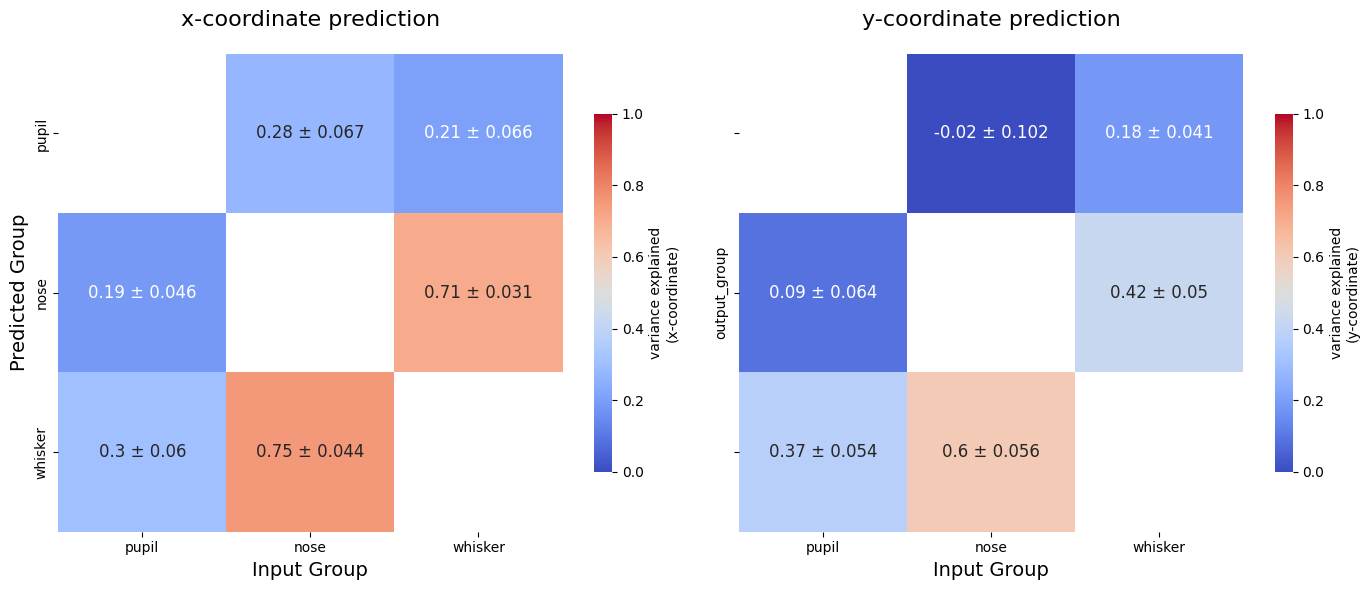

In [8]:
# Move any torch tensors in results dict to CPU and detach them
for k, v in results.items():
    if isinstance(v, list):
        results[k] = [x.cpu().detach() if torch.is_tensor(x) else x for x in v]
    elif torch.is_tensor(v):
        results[k] = v.cpu().detach()

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Exclude 'eye' group if it exists
results_df = results_df[(results_df['input_group'] != 'eye') & (results_df['output_group'] != 'eye')]

# Define desired order
group_order = ['pupil', 'nose', 'whisker']

def make_plot_df(metric):
    """Return mean, sem, and annotation DataFrames for the given metric (e.g., 'varexp_x')."""
    mean_df = (results_df.groupby(['output_group', 'input_group'])[metric].mean()
               .unstack()
               .reindex(index=group_order, columns=group_order))
    sem_df = (results_df.groupby(['output_group', 'input_group'])[metric].sem()
              .unstack()
              .reindex(index=group_order, columns=group_order))
    annot_df = mean_df.round(2).astype(str) + " ± " + sem_df.round(3).astype(str)
    return mean_df, annot_df

# Prepare both x and y data
plot_df_x, annot_df_x = make_plot_df('varexp_x')
plot_df_y, annot_df_y = make_plot_df('varexp_y')

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# ---- Left: x-coordinate ----
sns.heatmap(
    plot_df_x,
    annot=annot_df_x,
    fmt="",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    annot_kws={"size": 12},
    cbar_kws={'label': 'variance explained\n(x-coordinate)', 'shrink': 0.75},
    ax=axes[0]
)
axes[0].set_title("x-coordinate prediction", fontsize=16, pad=20)
axes[0].set_ylabel("Predicted Group", fontsize=14)
axes[0].set_xlabel("Input Group", fontsize=14)

# ---- Right: y-coordinate ----
sns.heatmap(
    plot_df_y,
    annot=annot_df_y,
    fmt="",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    annot_kws={"size": 12},
    cbar_kws={'label': 'variance explained\n(y-coordinate)', 'shrink': 0.75},
    ax=axes[1]
)
axes[1].set_title("y-coordinate prediction", fontsize=16, pad=20)
axes[1].set_xlabel("Input Group", fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
results_filtered = {k: v for k, v in results.items() if k in ['mouse', 'input_group', 'output_group', 'varexp_x', 'varexp_y']}
np.savez(f"{BASE_FOLDER}data/saccade_data/bodypart_group_results_zscore.npz", **results_filtered)
